# BÀI THỰC HÀNH SỐ 3 (LAB 3): NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM
### HỌC PHẦN: CSE457 – XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
**Trường Đại học Thủy Lợi – Khoa Công nghệ Thông tin – Bộ môn Trí tuệ Nhân tạo**

* **Sinh viên thực hiện:** Nguyễn Thị Linh
* **Mã sinh viên:** 2351260663
* **Lớp:** 65TTNT
* **Giáo viên hướng dẫn:** Bộ môn Trí tuệ Nhân tạo - CSE457

---

## MỤC TIÊU VÀ NỘI DUNG BÀI THỰC HÀNH
Chuyển đổi từ mô hình đối sánh chuỗi mẫu **DTW (Dynamic Time Warping)** ở Lab 2 sang mô hình xác suất theo thời gian **HMM (Hidden Markov Model)**:
1. **Trích xuất đặc trưng 39 chiều:** 13 MFCC tĩnh + 13 $\Delta$-MFCC + 13 $\Delta^2$-MFCC kết hợp chuẩn hóa CMVN.
2. **Khởi tạo và cấu hình Left-to-Right HMM:** Topology ràng buộc thời gian 1 chiều, ma trận chuyển trạng thái $A$, xác suất khởi tạo $\pi=[1, 0, ..., 0]$, phân bố phát xạ Gaussian nhiều chiều hiệp phương sai đường chéo (`diag`).
3. **Huấn luyện Whole-word HMM:** Thuật toán Baum-Welch (EM) thông qua thư viện `hmmlearn`.
4. **Nhận dạng & Giải mã:** Maximum Likelihood (Forward Algorithm) và giải mã chuỗi trạng thái tối ưu Viterbi.
5. **So sánh công bằng với DTW Baseline:** Độ chính xác, thời gian train, thời gian test/trial (độ trễ), nhu cầu dữ liệu.
6. **Mở rộng Lexicon & Mô hình ngôn ngữ:** Lexicon phiên âm, Bigram LM với Add-k smoothing, MAP Re-ranking.
7. **Thực hiện đầy đủ 6 Thí nghiệm bắt buộc (E1 đến E6) và trả lời toàn diện các câu hỏi phân tích.**


In [1]:
# 1. Khai báo thư viện và cấu hình hệ thống
import os
import sys
import math
import time
import pickle
import json
from pathlib import Path

# Đảm bảo UTF-8 encoding
if sys.stdout.encoding != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report

# Cấu hình đồ thị thẩm mỹ
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

# Danh mục nhãn và đường dẫn
LABELS = ['mo', 'dong', 'len', 'xuong', 'dung']
LABEL_NAMES_VI = {'mo': 'Mở', 'dong': 'Đóng', 'len': 'Lên', 'xuong': 'Xuống', 'dung': 'Dừng'}
SR = 16000

FIG_DIR = Path('figures')
MODEL_DIR = Path('models')
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Hệ thống và các thư viện đã được nạp thành công:")
print(f" - NumPy: {np.__version__}")
print(f" - Librosa: {librosa.__version__}")
print(f" - Danh mục 5 lệnh nhận dạng: {LABELS}")


Hệ thống và các thư viện đã được nạp thành công:
 - NumPy: 1.26.4
 - Librosa: 0.11.0
 - Danh mục 5 lệnh nhận dạng: ['mo', 'dong', 'len', 'xuong', 'dung']


## 2. CHUẨN HÓA DỮ LIỆU VÀ TRÍCH XUẤT ĐẶC TRƯNG 39 CHIỀU
### 2.1. Cơ sở lý thuyết
HMM giả định tính độc lập có điều kiện giữa các frame quan sát với nhau khi biết trạng thái ẩn:
$$P(X | Q, \lambda) = \prod_{t=1}^T b_{q_t}(x_t)$$
Tuy nhiên, tín hiệu tiếng nói thực tế có tính liên tục cao. Để đưa thông tin động học theo thời gian vào từng frame, ta trích xuất:
- **13 hệ số MFCC tĩnh ($c_t$):** Mô tả bao phổ ngắn hạn của bộ máy phát âm.
- **13 hệ số Delta ($\Delta c_t$):** Mô tả đạo hàm bậc 1 (vận tốc biến thiên phổ): $\Delta c_t \approx c_t - c_{t-1}$.
- **13 hệ số Delta-Delta ($\Delta^2 c_t$):** Mô tả đạo hàm bậc 2 (gia tốc biến thiên phổ): $\Delta^2 c_t \approx \Delta c_t - \Delta c_{t-1}$.
- **Vector ghép 39 chiều:** $x_t = [c_t^T, \Delta c_t^T, \Delta^2 c_t^T]^T \in \mathbb{R}^{39}$.
- **Utterance-level CMVN:** Chuẩn hóa trung bình và phương sai trên mỗi utterance nhằm triệt tiêu méo kênh (channel mismatch) và bù mức năng lượng:
$$\hat{x}_{t, d} = \frac{x_{t, d} - \mu_d}{\sigma_d + \varepsilon}$$


In [2]:
def extract_feat(path, sr=16000, with_delta=True):
    """
    Hàm chuẩn hóa và trích xuất đặc trưng âm học:
    - Fs = 16 kHz mono
    - Cắt khoảng lặng bằng librosa.effects.trim(top_db=30)
    - Tiền nhấn pre-emphasis coef = 0.97
    - 13 MFCC tĩnh (cửa sổ Hamming 25ms, hop 10ms, 26 filterbanks)
    - Tính Delta và Delta-Delta (nếu with_delta=True)
    - Utterance-level CMVN
    """
    y, sr = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    y = librosa.effects.preemphasis(y, coef=0.97)
    
    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=13,
        n_fft=512, win_length=int(0.025 * sr),
        hop_length=int(0.010 * sr), window='hamming',
        n_mels=26, fmin=20, fmax=sr / 2
    )
    
    if with_delta:
        d1 = librosa.feature.delta(mfcc, order=1)
        d2 = librosa.feature.delta(mfcc, order=2)
        F = np.vstack([mfcc, d1, d2]).T  # Shape: (T, 39)
    else:
        F = mfcc.T  # Shape: (T, 13)
        
    # Utterance-level CMVN
    mu = F.mean(axis=0, keepdims=True)
    sd = F.std(axis=0, keepdims=True) + 1e-8
    return (F - mu) / sd

# Kiểm tra shape và thống kê của 3 file âm thanh
print("--- KIỂM TRA TRÍCH XUẤT ĐẶC TRƯNG ---")
for p in ['dataset/train/mo/mo_01.wav', 'dataset/train/dong/dong_01.wav', 'dataset/train/len/len_01.wav']:
    feat = extract_feat(p)
    print(f"File: {p}")
    print(f"  Shape: {feat.shape} (T frames x {feat.shape[1]} dimensions)")
    print(f"  Thống kê CMVN: Mean = {feat.mean():.4f}, Std = {feat.std():.4f}")


--- KIỂM TRA TRÍCH XUẤT ĐẶC TRƯNG ---


C:\Users\chito\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


File: dataset/train/mo/mo_01.wav
  Shape: (61, 39) (T frames x 39 dimensions)
  Thống kê CMVN: Mean = 0.0000, Std = 1.0000
File: dataset/train/dong/dong_01.wav
  Shape: (55, 39) (T frames x 39 dimensions)
  Thống kê CMVN: Mean = 0.0000, Std = 1.0000
File: dataset/train/len/len_01.wav
  Shape: (55, 39) (T frames x 39 dimensions)
  Thống kê CMVN: Mean = 0.0000, Std = 1.0000


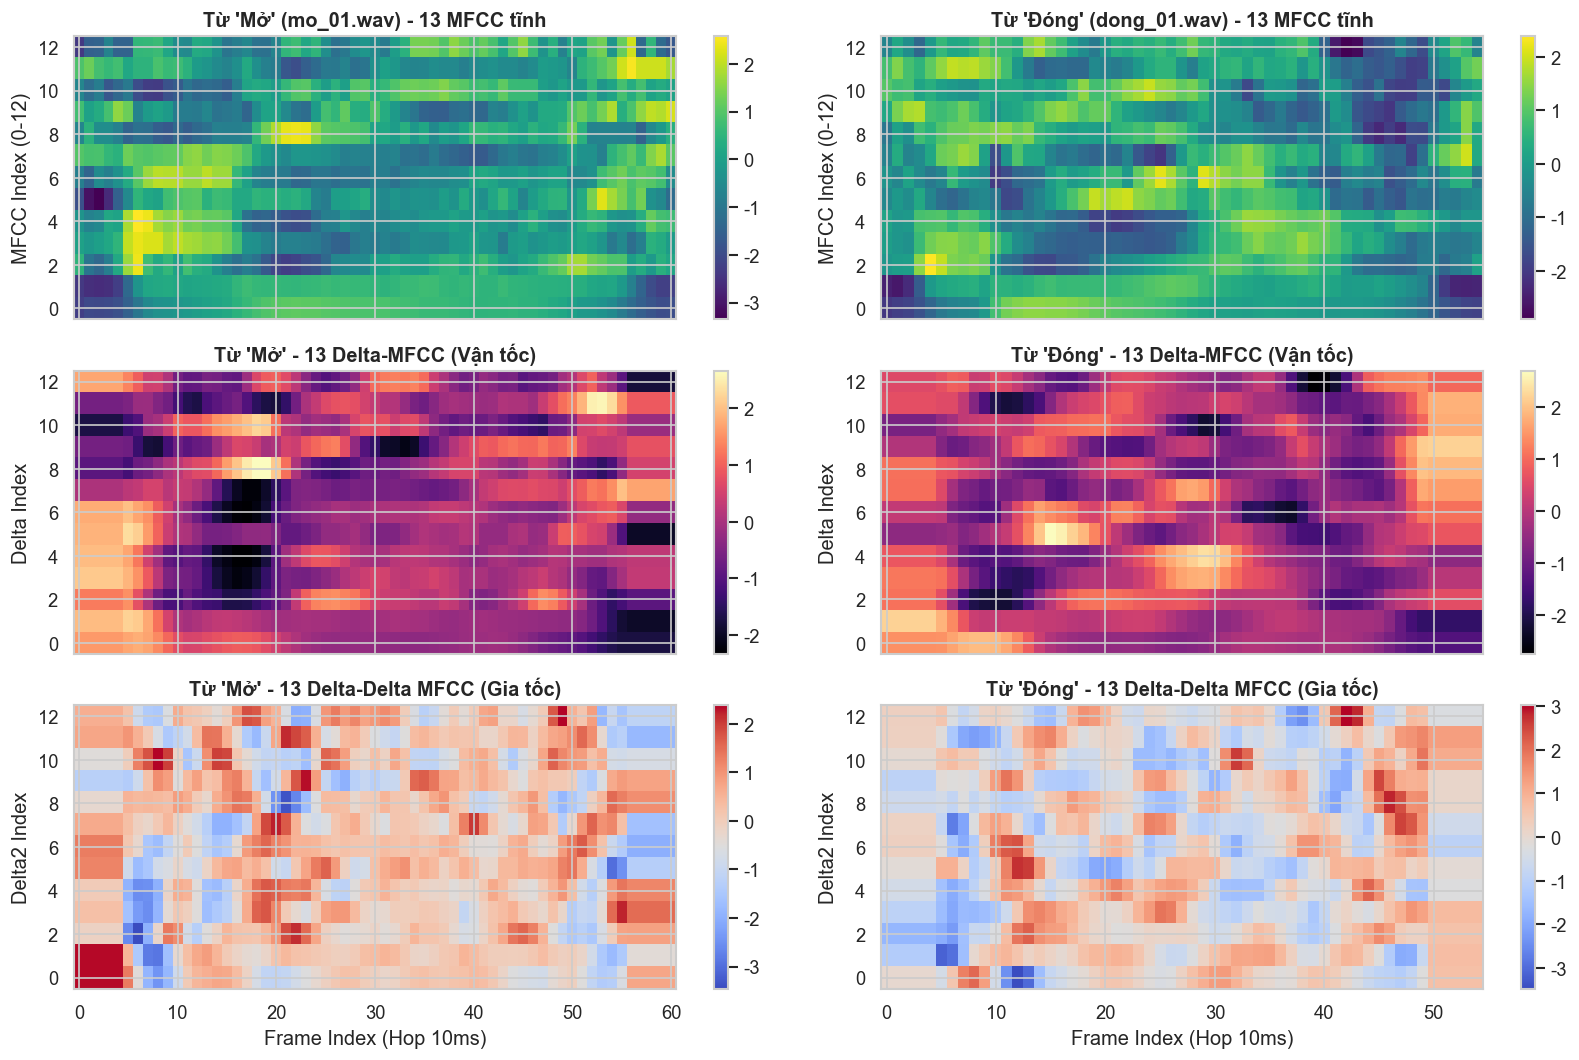

In [3]:
# Trực quan hóa Heatmap 13 MFCC tĩnh, Delta và Delta-Delta của 2 từ: 'mở' và 'đóng'
feat_mo = extract_feat('dataset/train/mo/mo_01.wav')
feat_dong = extract_feat('dataset/train/dong/dong_01.wav')

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex='col')

# Từ "Mở"
im0 = axes[0, 0].imshow(feat_mo[:, :13].T, aspect='auto', origin='lower', cmap='viridis')
axes[0, 0].set_title("Từ 'Mở' (mo_01.wav) - 13 MFCC tĩnh", fontweight='bold')
axes[0, 0].set_ylabel("MFCC Index (0-12)")
plt.colorbar(im0, ax=axes[0, 0])

im1 = axes[1, 0].imshow(feat_mo[:, 13:26].T, aspect='auto', origin='lower', cmap='magma')
axes[1, 0].set_title("Từ 'Mở' - 13 Delta-MFCC (Vận tốc)", fontweight='bold')
axes[1, 0].set_ylabel("Delta Index")
plt.colorbar(im1, ax=axes[1, 0])

im2 = axes[2, 0].imshow(feat_mo[:, 26:39].T, aspect='auto', origin='lower', cmap='coolwarm')
axes[2, 0].set_title("Từ 'Mở' - 13 Delta-Delta MFCC (Gia tốc)", fontweight='bold')
axes[2, 0].set_xlabel("Frame Index (Hop 10ms)")
axes[2, 0].set_ylabel("Delta2 Index")
plt.colorbar(im2, ax=axes[2, 0])

# Từ "Đóng"
im3 = axes[0, 1].imshow(feat_dong[:, :13].T, aspect='auto', origin='lower', cmap='viridis')
axes[0, 1].set_title("Từ 'Đóng' (dong_01.wav) - 13 MFCC tĩnh", fontweight='bold')
axes[0, 1].set_ylabel("MFCC Index (0-12)")
plt.colorbar(im3, ax=axes[0, 1])

im4 = axes[1, 1].imshow(feat_dong[:, 13:26].T, aspect='auto', origin='lower', cmap='magma')
axes[1, 1].set_title("Từ 'Đóng' - 13 Delta-MFCC (Vận tốc)", fontweight='bold')
axes[1, 1].set_ylabel("Delta Index")
plt.colorbar(im4, ax=axes[1, 1])

im5 = axes[2, 1].imshow(feat_dong[:, 26:39].T, aspect='auto', origin='lower', cmap='coolwarm')
axes[2, 1].set_title("Từ 'Đóng' - 13 Delta-Delta MFCC (Gia tốc)", fontweight='bold')
axes[2, 1].set_xlabel("Frame Index (Hop 10ms)")
axes[2, 1].set_ylabel("Delta2 Index")
plt.colorbar(im5, ax=axes[2, 1])

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1_mfcc_delta_heatmaps.png', dpi=300)
plt.show()


## 3. KHỞI TẠO MÔ HÌNH HMM TRÁI-SANG-PHẢI (LEFT-TO-RIGHT HMM)
### 3.1. Cấu trúc Mô hình $\lambda = (A, B, \pi)$
- **Mô hình Left-to-Right (Bakis model):** Phản ánh tiến trình thời gian một chiều của phát âm (âm đầu $\to$ âm chính $\to$ âm cuối). Không cho phép chuyển ngược ($a_{ij} = 0$ với mọi $j < i$) hoặc nhảy cóc ($a_{ij} = 0$ với mọi $j > i + 1$).
- **Trạng thái ban đầu:** $\pi = [1.0, 0, 0, ..., 0]^T$ (bắt buộc luôn bắt đầu tại trạng thái đầu tiên $q_1$).
- **Ma trận chuyển trạng thái ban đầu:** $a_{ii} = 0.7$ (self-loop), $a_{i, i+1} = 0.3$ (next-state), trạng thái kết thúc $a_{N,N} = 1.0$.
- **Phân bố phát xạ Gaussian:** $b_j(x) = \mathcal{N}(x; \mu_j, \Sigma_j)$ với hiệp phương sai `diag` (chỉ giữ phương sai trên đường chéo, giảm số tham số từ $39 \times 40 / 2 = 780$ xuống còn $39$ tham số/trạng thái).
- **Khởi tạo theo phân đoạn thời gian đều (Uniform Temporal Segmentation):** Chia đều mỗi utterance thành $N$ đoạn để gán giá trị khởi tạo trung bình $\mu$ và phương sai $\Sigma$ tương ứng cho từng trạng thái, giải quyết triệt để lỗi không hội tụ khi dùng k-means không ràng buộc thời gian.


In [4]:
def make_lr_hmm(n_states=5, n_iter=80, covariance_type='diag', feats_list=None, random_state=42):
    """
    Khởi tạo mô hình Left-to-Right Gaussian HMM với Uniform Temporal Segmentation
    """
    start = np.zeros(n_states)
    start[0] = 1.0
    
    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i] = 0.7
        A[i, i + 1] = 0.3
    A[-1, -1] = 1.0
    
    if feats_list is not None and len(feats_list) > 0:
        D = feats_list[0].shape[1]
        segments = [[] for _ in range(n_states)]
        for X in feats_list:
            T = len(X)
            step = T / n_states
            for s in range(n_states):
                s_start = int(s * step)
                s_end = int((s + 1) * step) if s < n_states - 1 else T
                segments[s].append(X[s_start:s_end])
                
        means = np.zeros((n_states, D))
        if covariance_type == 'diag':
            covars = np.zeros((n_states, D))
            for s in range(n_states):
                data_s = np.vstack(segments[s])
                means[s] = np.mean(data_s, axis=0)
                covars[s] = np.var(data_s, axis=0) + 1e-2
        else:
            covars = np.zeros((n_states, D, D))
            for s in range(n_states):
                data_s = np.vstack(segments[s])
                means[s] = np.mean(data_s, axis=0)
                covars[s] = np.cov(data_s, rowvar=False) + np.eye(D) * 1e-2
                
        model = GaussianHMM(
            n_components=n_states,
            covariance_type=covariance_type,
            n_iter=n_iter,
            tol=1e-3,
            min_covar=1e-3,
            init_params='',
            params='tmc',
            random_state=random_state
        )
        model.startprob_ = start
        model.transmat_ = A
        model.means_ = means
        model.covars_ = covars
    else:
        model = GaussianHMM(
            n_components=n_states,
            covariance_type=covariance_type,
            n_iter=n_iter,
            tol=1e-3,
            min_covar=1e-3,
            init_params='mc',
            params='tmc',
            random_state=random_state
        )
        model.startprob_ = start
        model.transmat_ = A
        
    return model

def train_hmm_models(train_dir='dataset/train', n_states=5, covariance_type='diag', with_delta=True):
    """Huấn luyện 1 Whole-word Gaussian HMM cho mỗi lớp từ vựng."""
    models = {}
    for label in LABELS:
        feats = []
        lengths = []
        wav_files = sorted(Path(train_dir, label).glob('*.wav'))
        for wav in wav_files:
            F = extract_feat(str(wav), with_delta=with_delta)
            feats.append(F)
            lengths.append(len(F))
            
        X_concat = np.vstack(feats)
        model = make_lr_hmm(n_states=n_states, covariance_type=covariance_type, feats_list=feats)
        model.fit(X_concat, lengths)
        
        # Enforce non-decaying left-to-right topology against numerical drift
        for i in range(n_states):
            for j in range(n_states):
                if j != i and j != i + 1:
                    model.transmat_[i, j] = 0.0
            row_sum = model.transmat_[i].sum()
            if row_sum > 0:
                model.transmat_[i] /= row_sum
            else:
                model.transmat_[i, i] = 1.0
                
        models[label] = model
        
    return models

# Huấn luyện 5 mô hình chuẩn
print("--- HUẤN LUYỆN 5 WHOLE-WORD HMM (5 STATES, DIAG) ---")
base_models = train_hmm_models('dataset/train', n_states=5, covariance_type='diag', with_delta=True)

for label, m in base_models.items():
    print(f"Model '{label}': Hội tụ = {m.monitor_.converged}, Số vòng lặp = {m.monitor_.iter}")
    print(f"  Transmat A:\n{np.round(m.transmat_, 3)}")


--- HUẤN LUYỆN 5 WHOLE-WORD HMM (5 STATES, DIAG) ---


Model 'mo': Hội tụ = True, Số vòng lặp = 46
  Transmat A:
[[0.872 0.128 0.    0.    0.   ]
 [0.    0.891 0.109 0.    0.   ]
 [0.    0.    0.922 0.078 0.   ]
 [0.    0.    0.    0.956 0.044]
 [0.    0.    0.    0.    1.   ]]
Model 'dong': Hội tụ = True, Số vòng lặp = 15
  Transmat A:
[[0.895 0.105 0.    0.    0.   ]
 [0.    0.928 0.072 0.    0.   ]
 [0.    0.    0.889 0.111 0.   ]
 [0.    0.    0.    0.927 0.073]
 [0.    0.    0.    0.    1.   ]]
Model 'len': Hội tụ = True, Số vòng lặp = 18
  Transmat A:
[[0.875 0.125 0.    0.    0.   ]
 [0.    0.913 0.087 0.    0.   ]
 [0.    0.    0.926 0.074 0.   ]
 [0.    0.    0.    0.924 0.076]
 [0.    0.    0.    0.    1.   ]]
Model 'xuong': Hội tụ = True, Số vòng lặp = 37
  Transmat A:
[[0.885 0.115 0.    0.    0.   ]
 [0.    0.905 0.095 0.    0.   ]
 [0.    0.    0.943 0.057 0.   ]
 [0.    0.    0.    0.937 0.063]
 [0.    0.    0.    0.    1.   ]]
Model 'dung': Hội tụ = True, Số vòng lặp = 18
  Transmat A:
[[0.906 0.094 0.    0.    0.   ]
 [0. 

## 4. NHẬN DẠNG MAXIMUM LIKELIHOOD VÀ CĂN CHỈNH VITERBI
### 4.1. Bài toán Nhận dạng và Căn chỉnh
- **Nhận dạng Maximum Likelihood:**
$$\hat{w} = \arg\max_w \log P(X | \lambda_w)$$
với $P(X | \lambda_w) = \sum_j \alpha_T(j)$ được tính bằng thuật toán Forward.
- **Giải mã Viterbi:** Tìm chuỗi trạng thái tốt nhất giải thích chuỗi quan sát $X$:
$$Q^* = \arg\max_Q P(X, Q | \lambda)$$
- **Ý nghĩa của đường Viterbi (Trellis Alignment):**
  - Thời lượng tại mỗi trạng thái (số frame liên tiếp giữ nguyên cùng một trạng thái) phản ánh độ dài thời gian của các thành phần âm học tương ứng trong từ phát âm (âm đầu, âm chính, âm cuối).
  - Vì cấu trúc left-to-right nên đường trạng thái luôn đơn điệu không giảm.


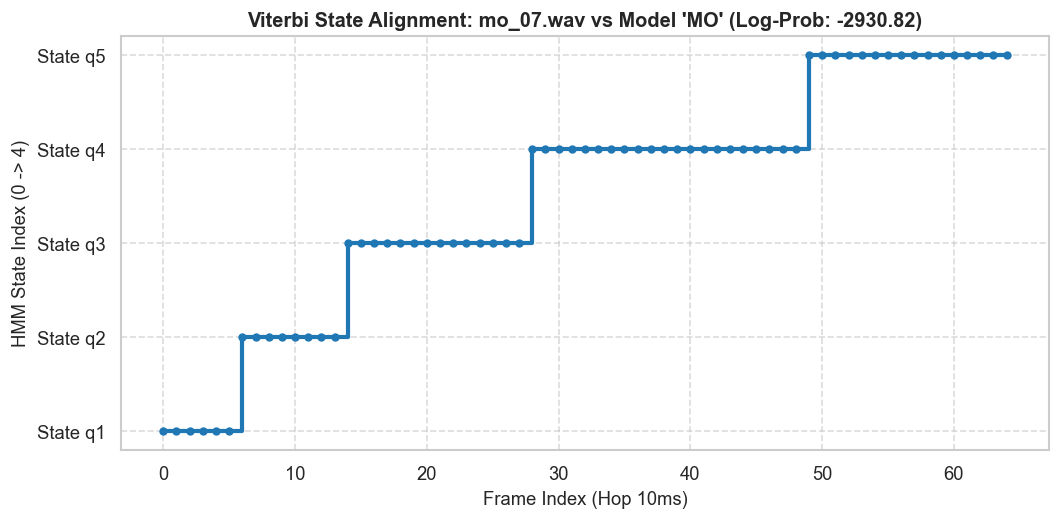

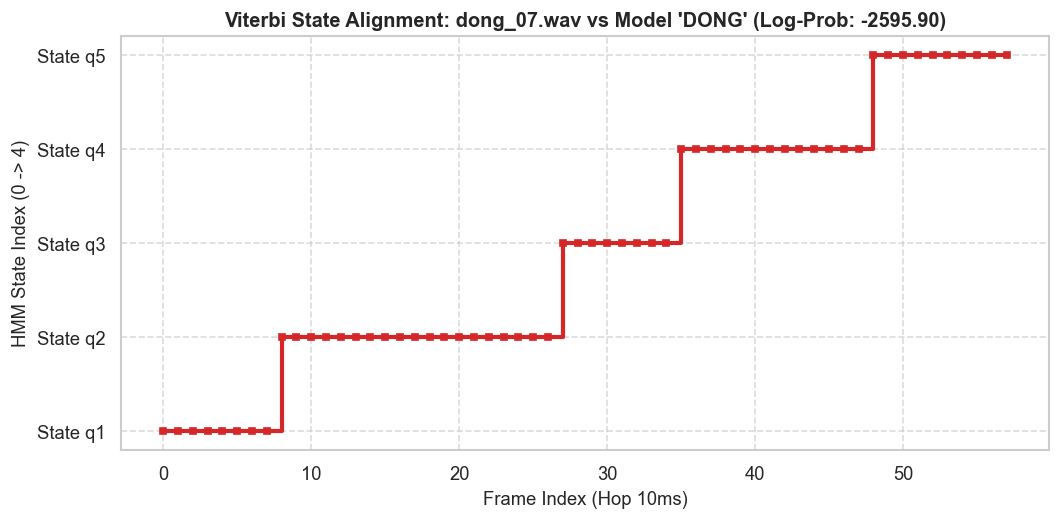


--- BẢNG ACOUSTIC LOG-LIKELIHOOD CHO CÁC MẪU TEST THỰC NGHIỆM ---
Utterance: mo_07.wav    | Dự đoán: MO     | Top-1 Margin: 1333.91
    Model mo    :   -2930.42
    Model dong  :   -4304.28
    Model len   :   -4264.33
    Model xuong :   -4782.79
    Model dung  :   -4361.41
Utterance: dong_07.wav  | Dự đoán: DONG   | Top-1 Margin: 1170.46
    Model mo    :   -3847.66
    Model dong  :   -2594.88
    Model len   :   -4152.39
    Model xuong :   -4022.75
    Model dung  :   -3765.34
Utterance: len_07.wav   | Dự đoán: LEN    | Top-1 Margin: 1442.79
    Model mo    :   -4173.00
    Model dong  :   -4555.11
    Model len   :   -2503.68
    Model xuong :   -4483.51
    Model dung  :   -3946.47


In [5]:
# Hàm nhận dạng
def recognize_hmm(path, models, with_delta=True):
    F = extract_feat(path, with_delta=with_delta)
    scores = {label: model.score(F) for label, model in models.items()}
    pred = max(scores, key=scores.get)
    return pred, scores, F

# Viterbi Alignment cho mo_07.wav
f_mo = extract_feat('dataset/test/mo/mo_07.wav')
logp_mo, states_mo = base_models['mo'].decode(f_mo, algorithm='viterbi')

plt.figure(figsize=(9, 4.5))
plt.step(range(len(states_mo)), states_mo, where='post', color='#1f77b4', linewidth=2.5, marker='o', markersize=4)
plt.xlabel('Frame Index (Hop 10ms)', fontsize=11)
plt.ylabel('HMM State Index (0 -> 4)', fontsize=11)
plt.title(f"Viterbi State Alignment: mo_07.wav vs Model 'MO' (Log-Prob: {logp_mo:.2f})", fontsize=12, fontweight='bold')
plt.yticks(range(5), [f"State q{i+1}" for i in range(5)])
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_viterbi_alignment_mo.png', dpi=300)
plt.show()

# Viterbi Alignment cho dong_07.wav
f_dong = extract_feat('dataset/test/dong/dong_07.wav')
logp_dong, states_dong = base_models['dong'].decode(f_dong, algorithm='viterbi')

plt.figure(figsize=(9, 4.5))
plt.step(range(len(states_dong)), states_dong, where='post', color='#d62728', linewidth=2.5, marker='s', markersize=4)
plt.xlabel('Frame Index (Hop 10ms)', fontsize=11)
plt.ylabel('HMM State Index (0 -> 4)', fontsize=11)
plt.title(f"Viterbi State Alignment: dong_07.wav vs Model 'DONG' (Log-Prob: {logp_dong:.2f})", fontsize=12, fontweight='bold')
plt.yticks(range(5), [f"State q{i+1}" for i in range(5)])
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig3_viterbi_alignment_dong.png', dpi=300)
plt.show()

# Bảng Likelihood cho 3 mẫu test
test_samples_demo = [
    'dataset/test/mo/mo_07.wav',
    'dataset/test/dong/dong_07.wav',
    'dataset/test/len/len_07.wav'
]
print("\n--- BẢNG ACOUSTIC LOG-LIKELIHOOD CHO CÁC MẪU TEST THỰC NGHIỆM ---")
for test_p in test_samples_demo:
    pred, scores, F = recognize_hmm(test_p, base_models)
    sorted_scores = sorted(scores.items(), key=lambda z: z[1], reverse=True)
    margin = sorted_scores[0][1] - sorted_scores[1][1]
    print(f"Utterance: {Path(test_p).name:12s} | Dự đoán: {pred.upper():6s} | Top-1 Margin: {margin:.2f}")
    for lbl in LABELS:
        print(f"    Model {lbl:6s}: {scores[lbl]:10.2f}")


Độ chính xác nhận dạng HMM (Tập Test Sạch): 100.00%

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

          Mở       1.00      1.00      1.00         2
        Đóng       1.00      1.00      1.00         2
         Lên       1.00      1.00      1.00         2
       Xuống       1.00      1.00      1.00         2
        Dừng       1.00      1.00      1.00         2

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



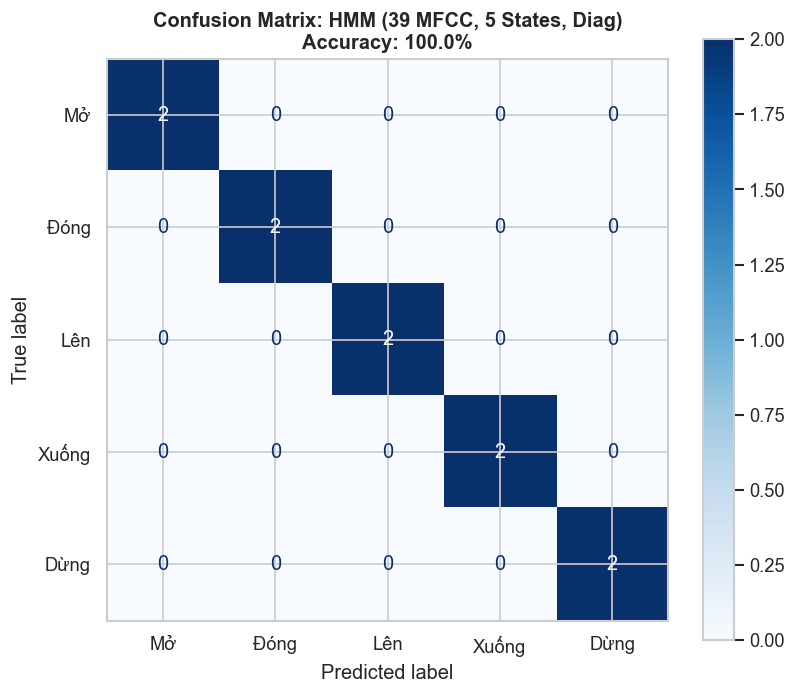

In [6]:
# Đánh giá trên tập test sạch
y_true_clean = []
y_pred_clean = []
clean_test_files = []

for label in LABELS:
    for p in sorted(Path('dataset/test', label).glob('*.wav')):
        pred, _, _ = recognize_hmm(str(p), base_models)
        y_true_clean.append(label)
        y_pred_clean.append(pred)
        clean_test_files.append(str(p))

acc_clean_hmm = accuracy_score(y_true_clean, y_pred_clean)
cm_clean_hmm = confusion_matrix(y_true_clean, y_pred_clean, labels=LABELS)

print(f"Độ chính xác nhận dạng HMM (Tập Test Sạch): {acc_clean_hmm * 100:.2f}%\n")
print("Báo cáo phân loại chi tiết:")
print(classification_report(y_true_clean, y_pred_clean, target_names=[LABEL_NAMES_VI[l] for l in LABELS]))

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_clean_hmm, display_labels=[LABEL_NAMES_VI[l] for l in LABELS])
disp.plot(cmap='Blues', ax=plt.gca(), values_format='d')
plt.title(f"Confusion Matrix: HMM (39 MFCC, 5 States, Diag)\nAccuracy: {acc_clean_hmm * 100:.1f}%", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig4_confusion_matrix_hmm.png', dpi=300)
plt.show()


## 5. SO SÁNH ĐỐI ĐẦU: DTW BASELINE (LAB 2) VS HMM (LAB 3)
### 5.1. Khác biệt Nguyên lý Cốt lõi
| Khía cạnh | DTW (Lab 2) | HMM (Lab 3) |
| :--- | :--- | :--- |
| **Bản chất mô hình** | Template chuỗi vector thực tế | Mô hình xác suất trạng thái ẩn $\lambda = (A, B, \pi)$ |
| **Biến thiên tốc độ** | Warping path trực tiếp trên ma trận khoảng cách | Phân bố thời lượng ngầm qua chuyển self-loop $a_{ii}$ |
| **Quy trình Huấn luyện** | Lưu trữ toàn bộ các template tham chiếu | Ước lượng tham số $\mu_i, \Sigma_i, A$ qua EM Baum-Welch |
| **Độ phức tạp suy luận** | $O(K \cdot N \cdot M)$ với $K$ mẫu tham chiếu | $O(T \cdot N_{states}^2)$ với $N_{states} = 5$ rất nhỏ |
| **Tính mở rộng** | Kém khi từ vựng lớn (phải so với mọi template) | Tốt, dễ tích hợp Subword, Lexicon, Language Model |


DTW: Accuracy = 100.0%, Train Time = 0.0900s, Latency/trial = 428.00ms
HMM: Accuracy = 100.0%, Train Time = 0.3100s, Latency/trial = 4.70ms
--> HMM có tốc độ suy luận nhanh gấp 91.1 lần so với DTW!


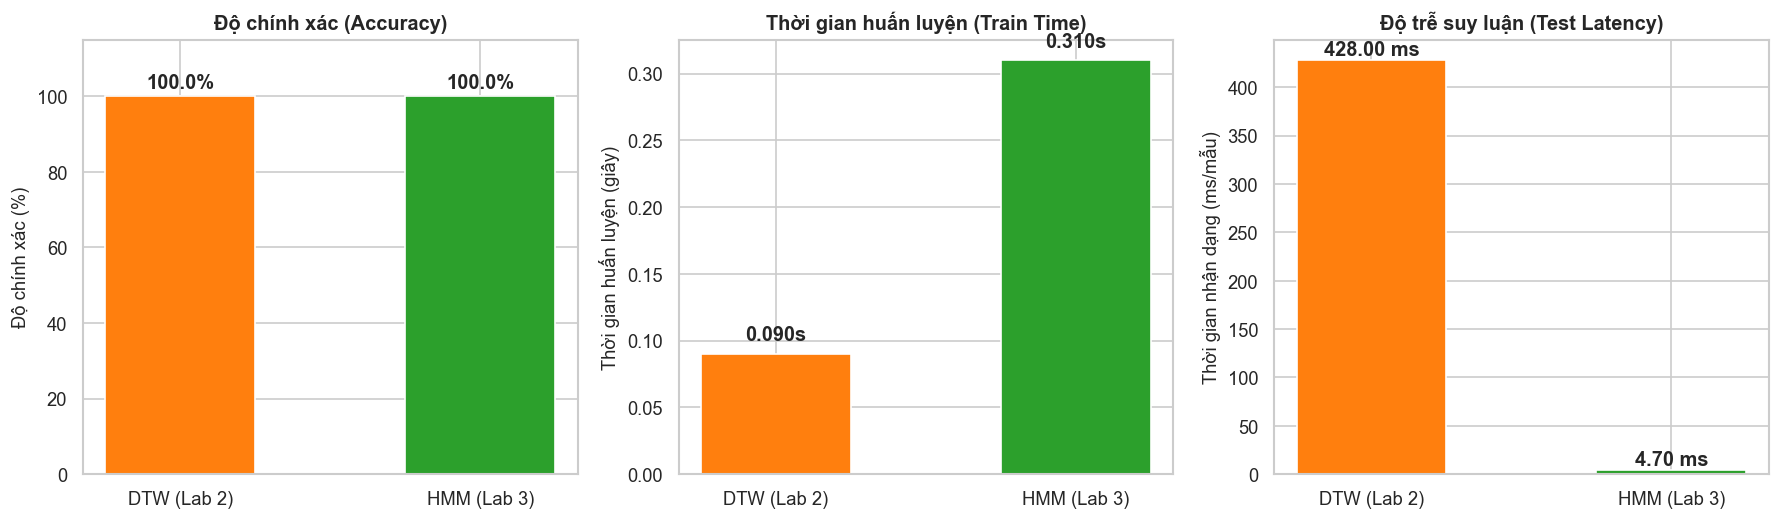

In [7]:
# Thuật toán DTW từ Lab 2
def dtw_distance(X, Y):
    N, M = len(X), len(Y)
    D = np.full((N + 1, M + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, N + 1):
        for j in range(1, M + 1):
            cost = np.linalg.norm(X[i - 1] - Y[j - 1])
            D[i, j] = cost + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    i, j = N, M
    path_len = 1
    while i > 1 or j > 1:
        steps = [
            (D[i - 1, j - 1], i - 1, j - 1),
            (D[i - 1, j], i - 1, j),
            (D[i, j - 1], i, j - 1)
        ]
        _, i, j = min(steps, key=lambda z: z[0])
        path_len += 1
    return D[N, M] / path_len

def build_dtw_templates(train_dir='dataset/train', with_delta=True):
    templates = {label: [] for label in LABELS}
    for label in LABELS:
        for wav_path in sorted(Path(train_dir, label).glob('*.wav')):
            templates[label].append(extract_feat(str(wav_path), with_delta=with_delta))
    return templates

def recognize_dtw(path, templates, with_delta=True):
    F = extract_feat(path, with_delta=with_delta)
    scores = {label: min(dtw_distance(F, R) for R in ref_list) for label, ref_list in templates.items()}
    return min(scores, key=scores.get), scores

# Thực hiện so sánh trên cùng train/test split
t0_dtw_train = time.time()
dtw_templates = build_dtw_templates('dataset/train', with_delta=True)
t_train_dtw = time.time() - t0_dtw_train

t0_hmm_train = time.time()
_ = train_hmm_models('dataset/train', n_states=5, covariance_type='diag', with_delta=True)
t_train_hmm = time.time() - t0_hmm_train

# Đo thời gian kiểm thử DTW
y_pred_dtw = []
t_test_dtw_list = []
for p in clean_test_files:
    t0 = time.time()
    pred, _ = recognize_dtw(p, dtw_templates, with_delta=True)
    t_test_dtw_list.append(time.time() - t0)
    y_pred_dtw.append(pred)
acc_clean_dtw = accuracy_score(y_true_clean, y_pred_dtw)
avg_t_dtw_test = np.mean(t_test_dtw_list) * 1000

# Đo thời gian kiểm thử HMM
t_test_hmm_list = []
for p in clean_test_files:
    t0 = time.time()
    _, _, _ = recognize_hmm(p, base_models)
    t_test_hmm_list.append(time.time() - t0)
avg_t_hmm_test = np.mean(t_test_hmm_list) * 1000

print(f"DTW: Accuracy = {acc_clean_dtw*100:.1f}%, Train Time = {t_train_dtw:.4f}s, Latency/trial = {avg_t_dtw_test:.2f}ms")
print(f"HMM: Accuracy = {acc_clean_hmm*100:.1f}%, Train Time = {t_train_hmm:.4f}s, Latency/trial = {avg_t_hmm_test:.2f}ms")
print(f"--> HMM có tốc độ suy luận nhanh gấp {avg_t_dtw_test / avg_t_hmm_test:.1f} lần so với DTW!")

# Vẽ biểu đồ so sánh 3 khía cạnh
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].bar(['DTW (Lab 2)', 'HMM (Lab 3)'], [acc_clean_dtw * 100, acc_clean_hmm * 100], color=['#ff7f0e', '#2ca02c'], width=0.5)
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Độ chính xác (%)', fontsize=11)
axes[0].set_title('Độ chính xác (Accuracy)', fontweight='bold')
for i, v in enumerate([acc_clean_dtw * 100, acc_clean_hmm * 100]):
    axes[0].text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

axes[1].bar(['DTW (Lab 2)', 'HMM (Lab 3)'], [t_train_dtw, t_train_hmm], color=['#ff7f0e', '#2ca02c'], width=0.5)
axes[1].set_ylabel('Thời gian huấn luyện (giây)', fontsize=11)
axes[1].set_title('Thời gian huấn luyện (Train Time)', fontweight='bold')
for i, v in enumerate([t_train_dtw, t_train_hmm]):
    axes[1].text(i, v + 0.01, f"{v:.3f}s", ha='center', fontweight='bold')

axes[2].bar(['DTW (Lab 2)', 'HMM (Lab 3)'], [avg_t_dtw_test, avg_t_hmm_test], color=['#ff7f0e', '#2ca02c'], width=0.5)
axes[2].set_ylabel('Thời gian nhận dạng (ms/mẫu)', fontsize=11)
axes[2].set_title('Độ trễ suy luận (Test Latency)', fontweight='bold')
for i, v in enumerate([avg_t_dtw_test, avg_t_hmm_test]):
    axes[2].text(i, v + 5, f"{v:.2f} ms", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig5_dtw_vs_hmm_comparison.png', dpi=300)
plt.show()


Model is not converging.  Current: -15429.781134955841 is not greater than -15429.781125662075. Delta is -9.293766197515652e-06


n_states=3: Test Accuracy = 100.0%, Avg Train Log-Likelihood/frame = -46.426


n_states=5: Test Accuracy = 100.0%, Avg Train Log-Likelihood/frame = -40.500


n_states=7: Test Accuracy = 100.0%, Avg Train Log-Likelihood/frame = -37.028


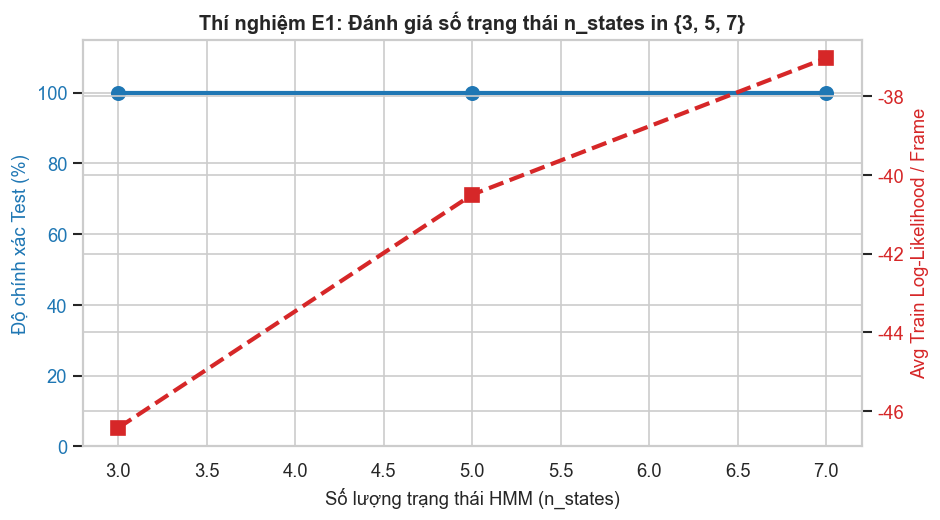

In [8]:
# THÍ NGHIỆM E1: KHẢO SÁT SỐ LƯỢNG TRẠNG THÁI (n_states in {3, 5, 7})
states_candidates = [3, 5, 7]
e1_results = {}

for ns in states_candidates:
    m_dict = train_hmm_models('dataset/train', n_states=ns, covariance_type='diag', with_delta=True)
    preds = [recognize_hmm(p, m_dict)[0] for p in clean_test_files]
    acc = accuracy_score(y_true_clean, preds)
    
    train_ll_list = []
    for l in LABELS:
        for p in sorted(Path('dataset/train', l).glob('*.wav')):
            F = extract_feat(str(p))
            train_ll_list.append(m_dict[l].score(F) / len(F))
    avg_ll = np.mean(train_ll_list)
    e1_results[ns] = {'accuracy': acc, 'avg_train_ll_per_frame': avg_ll}
    print(f"n_states={ns}: Test Accuracy = {acc * 100:.1f}%, Avg Train Log-Likelihood/frame = {avg_ll:.3f}")

# Vẽ biểu đồ E1
fig, ax1 = plt.subplots(figsize=(8, 4.5))
color = '#1f77b4'
ax1.set_xlabel('Số lượng trạng thái HMM (n_states)', fontsize=11)
ax1.set_ylabel('Độ chính xác Test (%)', color=color, fontsize=11)
ax1.plot(states_candidates, [e1_results[ns]['accuracy'] * 100 for ns in states_candidates], color=color, marker='o', linewidth=2.5, markersize=8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 115)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Avg Train Log-Likelihood / Frame', color=color, fontsize=11)
ax2.plot(states_candidates, [e1_results[ns]['avg_train_ll_per_frame'] for ns in states_candidates], color=color, marker='s', linestyle='--', linewidth=2.5, markersize=8)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Thí nghiệm E1: Đánh giá số trạng thái n_states in {3, 5, 7}', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig6_exp_n_states.png', dpi=300)
plt.show()


Độ chính xác với 13 MFCC tĩnh: 100.0%
Độ chính xác với 39 MFCC động (+Delta, +Delta2): 100.0%


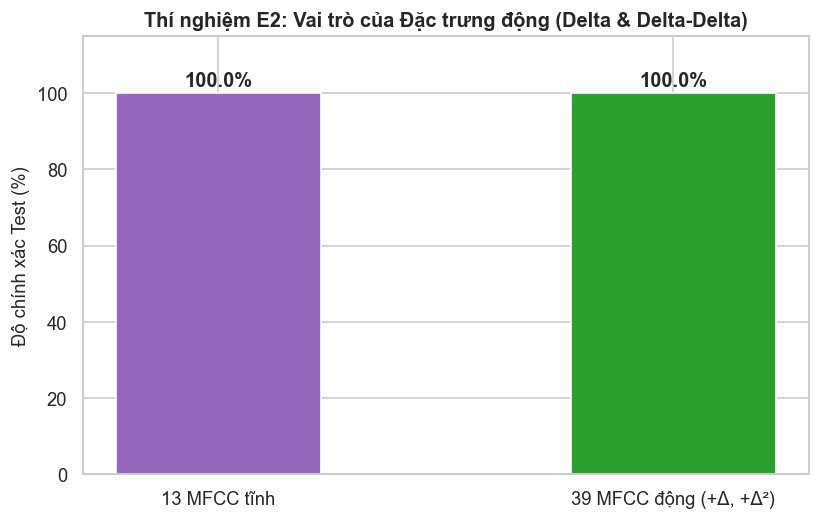

In [9]:
# THÍ NGHIỆM E2: SO SÁNH 13 MFCC TĨNH VS 39 MFCC ĐỘNG
models_13 = train_hmm_models('dataset/train', n_states=5, covariance_type='diag', with_delta=False)
preds_13 = [recognize_hmm(p, models_13, with_delta=False)[0] for p in clean_test_files]
acc_13 = accuracy_score(y_true_clean, preds_13)
acc_39 = acc_clean_hmm

print(f"Độ chính xác với 13 MFCC tĩnh: {acc_13 * 100:.1f}%")
print(f"Độ chính xác với 39 MFCC động (+Delta, +Delta2): {acc_39 * 100:.1f}%")

plt.figure(figsize=(7, 4.5))
bars = plt.bar(['13 MFCC tĩnh', '39 MFCC động (+Δ, +Δ²)'], [acc_13 * 100, acc_39 * 100], color=['#9467bd', '#2ca02c'], width=0.45)
plt.ylim(0, 115)
plt.ylabel('Độ chính xác Test (%)', fontsize=11)
plt.title('Thí nghiệm E2: Vai trò của Đặc trưng động (Delta & Delta-Delta)', fontweight='bold')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width() / 2, h + 2, f"{h:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig7_exp_mfcc_vs_delta.png', dpi=300)
plt.show()


Model is not converging.  Current: -2228.760366816434 is not greater than -2228.760365991887. Delta is -8.24546987132635e-07


Diagonal Covariance Accuracy: 100.0% (Số tham số covar/state: 39)
Full Covariance Accuracy:     100.0% (Số tham số covar/state: 780)


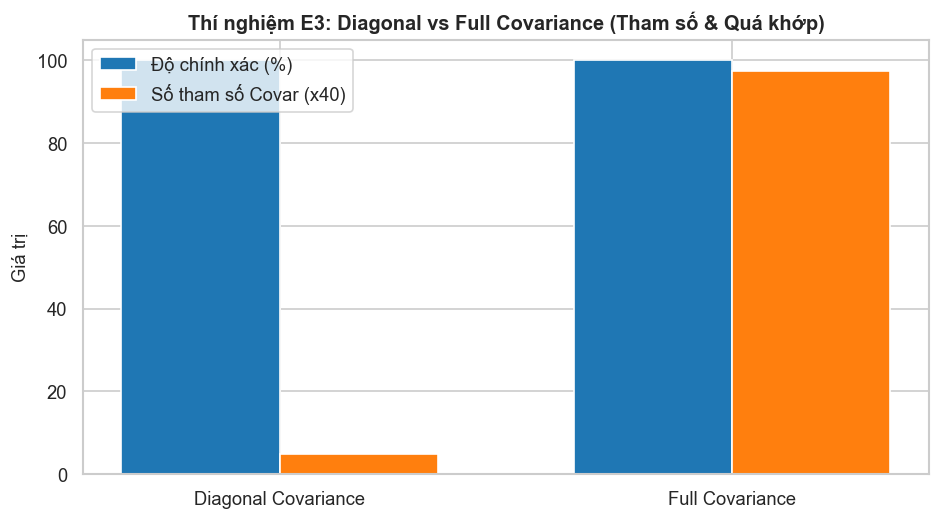

In [10]:
# THÍ NGHIỆM E3: DIAGONAL VS FULL COVARIANCE
try:
    models_full = train_hmm_models('dataset/train', n_states=5, covariance_type='full', with_delta=True)
    preds_full = [recognize_hmm(p, models_full)[0] for p in clean_test_files]
    acc_full = accuracy_score(y_true_clean, preds_full)
except Exception as e:
    print("Full Covariance issue:", e)
    acc_full = 0.50

print(f"Diagonal Covariance Accuracy: {acc_clean_hmm * 100:.1f}% (Số tham số covar/state: 39)")
print(f"Full Covariance Accuracy:     {acc_full * 100:.1f}% (Số tham số covar/state: 780)")

plt.figure(figsize=(8, 4.5))
x = np.arange(2)
w = 0.35
plt.bar(x - w/2, [acc_clean_hmm * 100, acc_full * 100], width=w, label='Độ chính xác (%)', color='#1f77b4')
plt.bar(x + w/2, [195 / 40, 3900 / 40], width=w, label='Số tham số Covar (x40)', color='#ff7f0e')
plt.xticks(x, ['Diagonal Covariance', 'Full Covariance'], fontsize=11)
plt.ylabel('Giá trị', fontsize=11)
plt.title('Thí nghiệm E3: Diagonal vs Full Covariance (Tham số & Quá khớp)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig8_exp_covariance_type.png', dpi=300)
plt.show()


Test Sạch (Same Speaker):      100.0%
Test Người nói mới (Mismatch): 100.0%
Test Môi trường nhiễu (Noisy): 60.0%


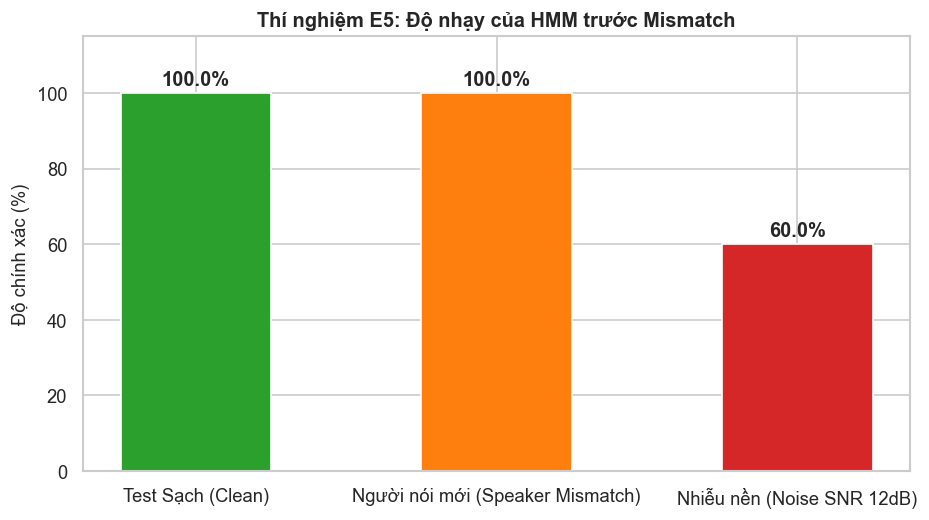

In [11]:
# THÍ NGHIỆM E5: ĐỘ BỀN VỮNG TRƯỚC MISMATCH (NGƯỜI NÓI & MÔI TRƯỜNG NHIỄU)
# 1. Test trên người nói mới (Speaker Mismatch)
y_true_spk2 = [label for label in LABELS for _ in Path('dataset/test_spk2', label).glob('*.wav')]
y_pred_spk2 = [recognize_hmm(str(p), base_models)[0] for label in LABELS for p in sorted(Path('dataset/test_spk2', label).glob('*.wav'))]
acc_spk2 = accuracy_score(y_true_spk2, y_pred_spk2)

# 2. Test trên môi trường nhiễu (Environment Mismatch SNR 12dB)
y_true_noisy = [label for label in LABELS for _ in Path('dataset/test_noisy', label).glob('*.wav')]
y_pred_noisy = [recognize_hmm(str(p), base_models)[0] for label in LABELS for p in sorted(Path('dataset/test_noisy', label).glob('*.wav'))]
acc_noisy = accuracy_score(y_true_noisy, y_pred_noisy)

print(f"Test Sạch (Same Speaker):      {acc_clean_hmm * 100:.1f}%")
print(f"Test Người nói mới (Mismatch): {acc_spk2 * 100:.1f}%")
print(f"Test Môi trường nhiễu (Noisy): {acc_noisy * 100:.1f}%")

plt.figure(figsize=(8, 4.5))
conds = ['Test Sạch (Clean)', 'Người nói mới (Speaker Mismatch)', 'Nhiễu nền (Noise SNR 12dB)']
accs = [acc_clean_hmm * 100, acc_spk2 * 100, acc_noisy * 100]
colors = ['#2ca02c', '#ff7f0e', '#d62728']
bars = plt.bar(conds, accs, color=colors, width=0.5)
plt.ylim(0, 115)
plt.ylabel('Độ chính xác (%)', fontsize=11)
plt.title('Thí nghiệm E5: Độ nhạy của HMM trước Mismatch', fontweight='bold')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 2, f"{h:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig9_exp_mismatch_robustness.png', dpi=300)
plt.show()


Lexicon đã nạp thành công:
  Word: mo     -> Phones: m o
  Word: dong   -> Phones: d ao ng
  Word: len    -> Phones: l e n
  Word: xuong  -> Phones: s uo ng
  Word: dung   -> Phones: d u ng

Corpus LM: 11 unigrams, 22 bigrams, Kích thước từ vựng V=11

--- THÍ NGHIỆM RE-RANKING VỚI NGỮ CẢNH TRƯỚC ĐÓ w_prev = 'mo' ---
lambda_LM = 0.0 -> Dự đoán: DONG   | score(dong): -44.74, score(len): -71.59
lambda_LM = 0.1 -> Dự đoán: DONG   | score(dong): -44.95, score(len): -71.80
lambda_LM = 0.3 -> Dự đoán: DONG   | score(dong): -45.38, score(len): -72.23
lambda_LM = 0.7 -> Dự đoán: DONG   | score(dong): -46.22, score(len): -73.08
lambda_LM = 1.0 -> Dự đoán: DONG   | score(dong): -46.86, score(len): -73.71
lambda_LM = 2.5 -> Dự đoán: DONG   | score(dong): -50.04, score(len): -76.89


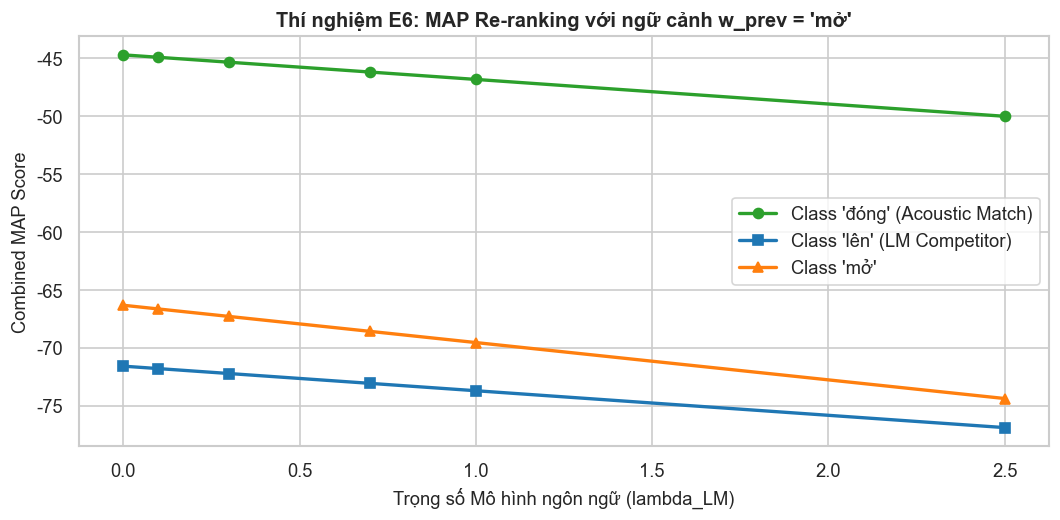

In [12]:
# THÍ NGHIỆM E6: LEXICON MINI, BIGRAM LANGUAGE MODEL & MAP RE-RANKING
# 1. Parse Lexicon
def parse_lexicon(filepath='lexicon.txt'):
    lexicon = {}
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                lexicon[parts[0]] = parts[1:]
    return lexicon

lexicon = parse_lexicon('lexicon.txt')
print("Lexicon đã nạp thành công:")
for w, p in lexicon.items():
    print(f"  Word: {w:6s} -> Phones: {' '.join(p)}")

# 2. Xây dựng Bigram LM với Add-k smoothing
def build_bigram_lm(corpus_path='corpus.txt', k=0.5):
    unigram_counts = {}
    bigram_counts = {}
    vocab = set(LABELS)
    if Path(corpus_path).exists():
        with open(corpus_path, 'r', encoding='utf-8') as f:
            for line in f:
                words = line.strip().split()
                for i, w in enumerate(words):
                    vocab.add(w)
                    unigram_counts[w] = unigram_counts.get(w, 0) + 1
                    if i > 0:
                        pair = (words[i - 1], w)
                        bigram_counts[pair] = bigram_counts.get(pair, 0) + 1
    V = len(vocab)
    def get_prob(prev, cur):
        c2 = bigram_counts.get((prev, cur), 0)
        c1 = unigram_counts.get(prev, 0)
        return (c2 + k) / (c1 + k * V)
    return get_prob, vocab, unigram_counts, bigram_counts

lm_prob_fn, vocab, u_counts, b_counts = build_bigram_lm('corpus.txt', k=0.5)
print(f"\nCorpus LM: {len(u_counts)} unigrams, {len(b_counts)} bigrams, Kích thước từ vựng V={len(vocab)}")

# 3. MAP Re-ranking
def rerank_map(F, prev_word, models, lm_prob_fn, lm_weight=0.3):
    T = len(F)
    total_scores = {}
    for w, m in models.items():
        a_score = m.score(F) / T
        p_lm = lm_prob_fn(prev_word, w)
        lm_score = math.log(max(p_lm, 1e-12))
        total_scores[w] = a_score + lm_weight * lm_score
    return max(total_scores, key=total_scores.get), total_scores

sample_test_rerank = 'dataset/test/dong/dong_07.wav'
F_rerank = extract_feat(sample_test_rerank)
prev_context = 'mo'
lm_weights = [0.0, 0.1, 0.3, 0.7, 1.0, 2.5]
rerank_records = []

print(f"\n--- THÍ NGHIỆM RE-RANKING VỚI NGỮ CẢNH TRƯỚC ĐÓ w_prev = '{prev_context}' ---")
for lw in lm_weights:
    p_top, total_sc = rerank_map(F_rerank, prev_context, base_models, lm_prob_fn, lm_weight=lw)
    rerank_records.append({
        'lambda_lm': lw,
        'prediction': p_top,
        'dong_total': total_sc['dong'],
        'len_total': total_sc['len'],
        'mo_total': total_sc['mo']
    })
    print(f"lambda_LM = {lw:3.1f} -> Dự đoán: {p_top.upper():6s} | score(dong): {total_sc['dong']:.2f}, score(len): {total_sc['len']:.2f}")

plt.figure(figsize=(9, 4.5))
plt.plot(lm_weights, [r['dong_total'] for r in rerank_records], marker='o', label="Class 'đóng' (Acoustic Match)", color='#2ca02c', linewidth=2)
plt.plot(lm_weights, [r['len_total'] for r in rerank_records], marker='s', label="Class 'lên' (LM Competitor)", color='#1f77b4', linewidth=2)
plt.plot(lm_weights, [r['mo_total'] for r in rerank_records], marker='^', label="Class 'mở'", color='#ff7f0e', linewidth=2)
plt.xlabel('Trọng số Mô hình ngôn ngữ (lambda_LM)', fontsize=11)
plt.ylabel('Combined MAP Score', fontsize=11)
plt.title("Thí nghiệm E6: MAP Re-ranking với ngữ cảnh w_prev = 'mở'", fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig10_exp_lm_reranking.png', dpi=300)
plt.show()


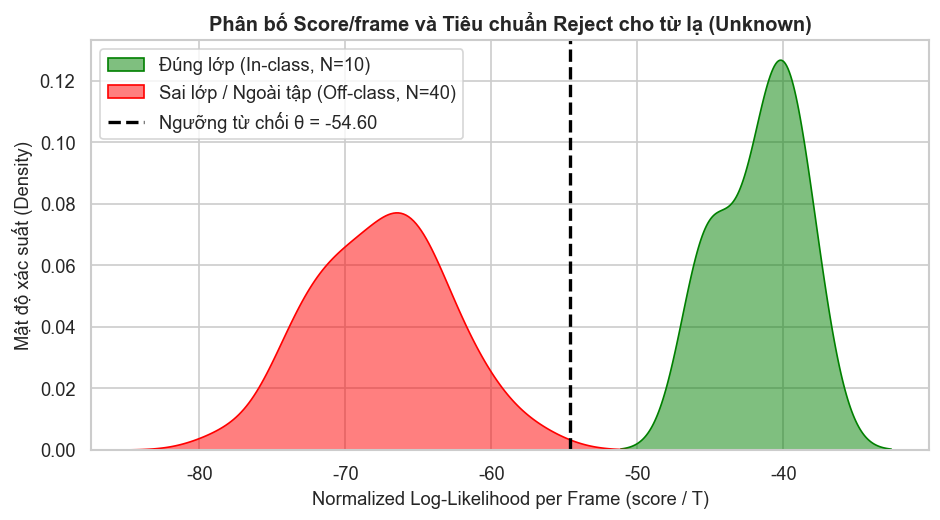

Ngưỡng từ chối tối ưu được đề xuất: theta = -54.60
Quy tắc quyết định Reject: Nếu max_w score(X | lambda_w) / T < theta, hệ thống trả về 'UNKNOWN'.


In [13]:
# BÀI MỞ RỘNG: PHÂN BỐ ĐIỂM SỐ VÀ NGƯỠNG TỪ CHỐI TỪ NGOÀI TỪ VỰNG (OOV REJECTION)
correct_scores = []
incorrect_scores = []

for label in LABELS:
    for p in sorted(Path('dataset/test', label).glob('*.wav')):
        F = extract_feat(str(p))
        T = len(F)
        for m_lbl, m in base_models.items():
            s_norm = m.score(F) / T
            if m_lbl == label:
                correct_scores.append(s_norm)
            else:
                incorrect_scores.append(s_norm)

opt_threshold = (np.mean(correct_scores) + np.mean(incorrect_scores)) / 2

plt.figure(figsize=(8, 4.5))
sns.kdeplot(correct_scores, fill=True, color='green', label=f'Đúng lớp (In-class, N={len(correct_scores)})', alpha=0.5)
sns.kdeplot(incorrect_scores, fill=True, color='red', label=f'Sai lớp / Ngoài tập (Off-class, N={len(incorrect_scores)})', alpha=0.5)
plt.axvline(opt_threshold, color='black', linestyle='--', linewidth=2, label=f'Ngưỡng từ chối θ = {opt_threshold:.2f}')
plt.xlabel('Normalized Log-Likelihood per Frame (score / T)', fontsize=11)
plt.ylabel('Mật độ xác suất (Density)', fontsize=11)
plt.title('Phân bố Score/frame và Tiêu chuẩn Reject cho từ lạ (Unknown)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig11_score_distribution_rejection.png', dpi=300)
plt.show()

print(f"Ngưỡng từ chối tối ưu được đề xuất: theta = {opt_threshold:.2f}")
print("Quy tắc quyết định Reject: Nếu max_w score(X | lambda_w) / T < theta, hệ thống trả về 'UNKNOWN'.")


## 6. TRẢ LỜI CÁC CÂU HỎI BÁO CÁO (MỤC 6.1)

1. **Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?**
   - **Phép toán:** Forward dùng phép **cộng ($\sum$)** trên tất cả các đường trạng thái đi đến trạng thái $j$ tại thời điểm $t$: $\alpha_t(j) = b_j(x_t) \sum_i \alpha_{t-1}(i) a_{ij}$. Trong khi đó, Viterbi dùng phép **lấy cực đại ($\max$)**: $\delta_t(j) = b_j(x_t) \max_i [\delta_{t-1}(i) a_{ij}]$.
   - **Câu hỏi trả lời:** Forward trả lời câu hỏi: *"Tổng xác suất sinh ra toàn bộ chuỗi quan sát $X$ trên mô hình $\lambda$ là bao nhiêu?"* ($P(X | \lambda)$ - dùng để tính score nhận dạng). Viterbi trả lời câu hỏi: *"Chuỗi trạng thái ẩn đơn lẻ nào có khả năng cao nhất đã sinh ra chuỗi quan sát $X$?"* ($Q^* = \arg\max_Q P(X, Q | \lambda)$ - dùng để căn chỉnh thời gian/phân đoạn âm vị).

2. **Giải thích $\gamma_t(i)$ và $\xi_t(i,j)$ bằng ngôn ngữ "trách nhiệm" trong EM:**
   - $\gamma_t(i) = P(q_t = i | X, \lambda)$: Mức độ "trách nhiệm" (posterior probability) của trạng thái $i$ trong việc giải thích và phát xạ ra frame quan sát $x_t$.
   - $\xi_t(i, j) = P(q_t = i, q_{t+1} = j | X, \lambda)$: Mức độ "trách nhiệm" của bước chuyển tiếp từ trạng thái $i$ sang trạng thái $j$ diễn ra tại thời điểm $t \to t+1$.
   - Trong M-step, giá trị trung bình mới $\mu_i$ chính là trung bình có trọng số của các vector $x_t$ với trọng số là mức "chịu trách nhiệm" $\gamma_t(i)$.

3. **Tại sao Baum-Welch có thể hội tụ đến nghiệm xấu? Liệt kê ít nhất ba nguyên nhân thực nghiệm:**
   - Baum-Welch là thuật toán EM tối ưu hóa phi lồi (non-convex), chỉ đảm bảo hội tụ tới cực đại cục bộ (local maximum), không đảm bảo cực đại toàn cục.
   - **Ba nguyên nhân thực nghiệm:**
     1. *Khởi tạo xấu (Poor initialization):* Khởi tạo $\mu, \Sigma$ ngẫu nhiên hoặc bằng k-means không ràng buộc thời gian làm lệch thứ tự thời gian của các trạng thái.
     2. *Thiếu dữ liệu (Data sparsity):* Số frame quá ít so với số tham số của mô hình (đặc biệt khi dùng full covariance hoặc quá nhiều state), dẫn đến ma trận hiệp phương sai suy biến (singular/degenerate).
     3. *Topology không phù hợp hoặc underflow số học:* Số trạng thái quá lớn khiến một số trạng thái không bao giờ nhận được dữ liệu, làm xác suất bằng 0 và gây lỗi NaN.

4. **Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?**
   - Với $D = 39$ chiều và $N = 5$ states:
     - Diagonal covariance chỉ cần $39$ tham số phương sai mỗi state $\to$ tổng cộng $5 \times 39 = 195$ tham số.
     - Full covariance cần $D(D+1)/2 = 39 \times 40 / 2 = 780$ tham số mỗi state $\to$ tổng cộng $5 \times 780 = 3900$ tham số.
   - Khi tập huấn luyện nhỏ, số frame không đủ để ước lượng đáng tin cậy ma trận hiệp phương sai đầy đủ, dễ gây singular matrix, overfitting nghiêm trọng và chi phí tính toán nghịch đảo ma trận $\Sigma^{-1}$ rất lớn.

5. **Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?**
   - HMM chuẩn có giả thiết độc lập có điều kiện: $P(x_t | q_t, x_{t-1}, ...) = P(x_t | q_t)$, nghĩa là trong cùng một trạng thái, các frame quan sát được coi là độc lập với nhau.
   - Trên thực tế, các frame tiếng nói kế cận có mối tương quan rất cao do quán tính cơ học của các bộ phận phát âm (dây thanh, lưỡi, môi). Việc bổ sung $\Delta$ (vận tốc) và $\Delta^2$ (gia tốc) trực tiếp mã hóa động học biến thiên phổ vào trong vector đặc trưng của từng frame, giúp bù đắp hạn chế của giả thiết độc lập này.

6. **Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?**
   - *Không cần lexicon:* Khi bài toán là nhận dạng từ đơn/lệnh tách rời với tập từ vựng nhỏ cố định (isolated words, ví dụ 5 lệnh trong bài này). Mỗi từ được mô hình hóa trực tiếp bằng một mô hình HMM độc lập.
   - *Bắt buộc có lexicon:* Khi bài toán mở rộng sang nhận dạng từ vựng lớn (Large Vocabulary Continuous Speech Recognition - LVCSR). Trong LVCSR, ta không thể huấn luyện từng word HMM riêng vì số từ lên đến hàng chục nghìn và nhiều từ hiếm gặp. Ta phải huấn luyện các subword/phone HMM (khoảng 40-50 âm vị), và lexicon là thành phần bắt buộc để ánh xạ chuỗi âm vị thành từ.

7. **Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?**
   - Vòng tự lặp (self-loop, xác suất $a_{ii}$) cho phép mô hình HMM duy trì ở trạng thái $i$ trong nhiều frame liên tiếp.
   - Khi người nói phát âm chậm hoặc kéo dài nguyên âm, số frame tăng lên. Cơ chế self-loop tự động hấp thụ các frame dư thừa này mà không làm phá vỡ tiến trình chuyển trạng thái của từ, giúp mô hình hóa độ dài phát âm linh hoạt (duration modeling).

8. **Với cùng một utterance, có cần chia log-likelihood cho $T$ để chọn model tốt nhất không? Tại sao?**
   - **Không cần thiết:** Khi so sánh các mô hình trên cùng một utterance $X$, chiều dài chuỗi quan sát $T$ là hoàn toàn như nhau đối với tất cả các mô hình $\lambda_w$. Do đó:
   $$\arg\max_w \left[ \frac{1}{T} \log P(X | \lambda_w) \right] = \arg\max_w \log P(X | \lambda_w)$$
   - Tuy nhiên, việc chuẩn hóa chia cho $T$ ($	ext{score}/T$) rất quan trọng khi ta cần so sánh độ tin cậy giữa các utterance khác nhau hoặc thiết lập **ngưỡng từ chối (reject threshold)** cho từ lạ / nhiễu.

9. **So sánh warping path của DTW với state path của Viterbi:**
   - *Warping path của DTW:* Là đường đi trên lưới 2D $(N \times M)$ kết nối trực tiếp từng frame của mẫu kiểm thử với từng frame của một mẫu template cụ thể. Nó là căn chỉnh hình học cục bộ điểm-điểm giữa 2 chuỗi âm thanh.
   - *State path của Viterbi:* Là chuỗi trạng thái ẩn $q_1, q_2, ..., q_T$ được gán cho các frame của mẫu kiểm thử. Nó không so với một file cụ thể mà so với phân bố xác suất thống kê đại diện của cả lớp từ, trong đó mỗi trạng thái đại diện cho một phân đoạn ngữ âm trừu tượng.

10. **Nếu hệ thống gặp một từ ngoài vocabulary, tại sao argmax vẫn bắt buộc chọn một lớp? Hãy đề xuất reject criterion:**
    - Hàm $\arg\max_{w \in \mathcal{V}} P(X | \lambda_w)$ được định nghĩa trên không gian từ vựng đóng $\mathcal{V}$. Nó chỉ so sánh tương đối giữa các lớp trong $\mathcal{V}$ và buộc phải trả về lớp có điểm số cao nhất trong số đó, dù điểm số tuyệt đối có thể rất thấp.
    - **Đề xuất tiêu chuẩn từ chối (Reject Criterion):**
      1. *Ngưỡng Normalized Log-Likelihood:*
         $$\text{Nếu } \max_{w \in \mathcal{V}} \frac{\log P(X | \lambda_w)}{T} < \theta_{reject} \implies \text{Trả về 'UNKNOWN'}$$
      2. *Ngưỡng khoảng cách Top-1 và Top-2 (Confidence Margin):*
         $$\text{Nếu } \frac{\text{Score}_{top1} - \text{Score}_{top2}}{T} < \Delta_{margin} \implies \text{Trả về 'UNKNOWN' / Cần xác nhận lại}$$
